# Exercise 1.3: Territorial analysis II (3 points): Person A

Report chapter: `report/chapters/03_territorial_analysis_II.tex`

**Sub-questions**

1. Working inhabitants per municipality, from the aggregated census (1 point)
2. Employees per municipality, from the URSSAF data (1 point)
3. Map of working inhabitants − employees; largest net outflow and largest net inflow (1 point)

**Reads**

- `data/processed/population_14.parquet` (aggregated census RP2019 per municipality, from Ex. 1.2)
- `data/processed/census_14.parquet` (detailed census, from Ex. 1.1; only for a cross-check)
- `data/processed/municipalities.gpkg` (528 municipalities, IGN CONTOURS-IRIS 2021, from Ex. 1.1)
- `data/raw/etablissements-et-effectifs-salaries-au-niveau-commune-x-ape-last_dep14.csv` (URSSAF, downloaded below if missing)
- `data/raw/v_mvt_commune_2026.csv` (INSEE COG 2026, changes of municipalities since 1943; downloaded below if missing)
- `data/raw/FD_MOBPRO_2019.csv` (INSEE commuting file MOBPRO RP2019; only for the validation section; downloaded below if missing)

**Writes**

- `data/processed/employment_14.parquet`: one row per municipality (528, sorted by `municipality_id`):
  `municipality_id`, `name`, `working_inhabitants`, `employees`, `difference` (for Ex. 2.1 / 2.2) and the MOBPRO
  reference `employed_residents_mobpro`, `jobs_mobpro`, `net_mobpro` (validation section)
- `data/processed/commutes_14.parquet`: MOBPRO origin–destination flows with both ends in the department
  (`origin_id`, `destination_id`, `weight`), as in the course notebook (for validating Ex. 2.3)
- `data/processed/ex13_results.json`: all numbers reported in Section 1.3 (unrounded)
- `report/figures/`: `working_inhabitants_top30`, `working_inhabitants_all`, `employees_top30`, `employees_all`,
  `inhabitants_minus_employees_map`, `inhabitants_minus_employees_scaled_map`, `net_commuting_mobpro_map`,
  `difference_vs_mobpro` (`.pdf` + `.png` previews)

## Setup and configuration

In [1]:
import json
import shutil
import urllib.parse
import urllib.request
import zipfile
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, SymLogNorm

# ---- Study area ------------------------------------------------------------------------
DEPARTMENT = "14"            # INSEE code of Calvados (region Normandie)
DEPARTMENT_NAME = "Calvados"
CRS = "EPSG:2154"            # RGF93 / Lambert-93, metres; all geometries and distances
GEOGRAPHY_DATE = "2021-01-01"   # municipality geography of the project (IGN CONTOURS-IRIS 2021, Ex. 1.1)

# ---- Paths -----------------------------------------------------------------------------
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "report").is_dir())
DATA_RAW = ROOT / "data" / "raw"
DATA_PROCESSED = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "report" / "figures"

POPULATION_PARQUET = DATA_PROCESSED / f"population_{DEPARTMENT}.parquet"   # from ex12, aggregated census RP2019
CENSUS_PARQUET = DATA_PROCESSED / f"census_{DEPARTMENT}.parquet"           # from ex11, detailed census RP2019
MUNICIPALITIES_GPKG = DATA_PROCESSED / "municipalities.gpkg"                # from ex11

# URSSAF "Nombre d'établissements employeurs et effectifs salariés du secteur privé, par commune x APE"
# (open.urssaf.fr, latest edition "-last"). CSV export restricted to the department with the API filter
# refine=code_departement:<DEPARTMENT>; same columns and labels as the full export used in the course notebook.
URSSAF_DATASET = "etablissements-et-effectifs-salaries-au-niveau-commune-x-ape-last"
URSSAF_API = f"https://open.urssaf.fr/api/explore/v2.1/catalog/datasets/{URSSAF_DATASET}"
URSSAF_EXPORT_URL = URSSAF_API + "/exports/csv?" + urllib.parse.urlencode({
    "lang": "fr", "timezone": "Europe/Berlin", "use_labels": "true", "delimiter": ";",
    "refine": f"code_departement:{DEPARTMENT}",
})
URSSAF_CSV = DATA_RAW / f"{URSSAF_DATASET}_dep{DEPARTMENT}.csv"
URSSAF_META_JSON = DATA_RAW / f"{URSSAF_DATASET}_dep{DEPARTMENT}_metadata.json"   # edition, written at download
URSSAF_YEAR = 2019                                      # same year as the census RP2019
URSSAF_EMPLOYEES = f"Effectifs salariés {URSSAF_YEAR}"

# INSEE Code officiel géographique 2026: changes of municipalities (mergers, code changes)
COG_CHANGES_URL = "https://www.insee.fr/fr/statistiques/fichier/8740222/v_mvt_commune_2026.csv"
COG_CHANGES_CSV = DATA_RAW / "v_mvt_commune_2026.csv"

# INSEE "Mobilités professionnelles des individus : déplacements commune de résidence / commune de travail"
# (MOBPRO, RP2019, geography 2021): one row per employed person (weighted), validation section only
MOBPRO_URL = "https://www.insee.fr/fr/statistiques/fichier/6456056/RP2019_mobpro_csv.zip"
MOBPRO_CSV = DATA_RAW / "FD_MOBPRO_2019.csv"
MOBPRO_VARMOD = DATA_RAW / "Varmod_MOBPRO_2019.csv"
MOBPRO_COLUMNS = {"COMMUNE": str, "ARM": str, "DCLT": str, "IPONDI": float, "TRANS": int}   # as in the course notebook
MOBPRO_CHUNKSIZE = 1_000_000
MOBPRO_ABROAD = "99999"     # DCLT of persons working abroad (DCFLT gives the foreign municipality)

EMPLOYMENT_PARQUET = DATA_PROCESSED / f"employment_{DEPARTMENT}.parquet"   # ex13 -> ex21_22
COMMUTES_PARQUET = DATA_PROCESSED / f"commutes_{DEPARTMENT}.parquet"       # ex13 -> ex23 (validation)
RESULTS_JSON = DATA_PROCESSED / "ex13_results.json"

# ---- Working inhabitants: population 15+ in SPC 1-6 (aggregated census) ------------------
SPC_LABELS = {
    1: "Agriculteurs exploitants",
    2: "Artisans, commerçants et chefs d'entreprise",
    3: "Cadres et professions intellectuelles supérieures",
    4: "Professions intermédiaires",
    5: "Employés",
    6: "Ouvriers",
    7: "Retraités",
    8: "Autres personnes sans activité professionnelle",
}
WORKING_SPC = [1, 2, 3, 4, 5, 6]                                   # 7 (retraités) and 8 (autres) excluded
WORKING_COLUMNS = [f"C19_POP15P_CS{k}" for k in WORKING_SPC]

# Activity status TACT of the detailed census (column `activity` of census_14.parquet, dictionary Varmod_INDCVI_2019.csv)
ACTIVITY_LABELS = {
    "11": "employed",            # actifs ayant un emploi, y compris apprentis et stagiaires rémunérés
    "12": "unemployed",          # chômeurs
    "21": "retired",             # retraités ou préretraités
    "22": "pupil/student",       # élèves, étudiants, stagiaires non rémunérés de 14 ans ou plus
    "23": "under 14",            # moins de 14 ans
    "24": "at home",             # femmes ou hommes au foyer
    "25": "other inactive",      # autres inactifs
}

# ---- Figures and tables ----------------------------------------------------------------
TOP_N = 30            # municipalities in the labelled bar plots
N_ANNOTATE = 5        # municipalities named in the all-municipality bar plots
N_TABLE = 5           # largest outflows / inflows in the table
SYMLOG_LINTHRESH = 100   # map colour scale: linear within +-100 persons, logarithmic beyond

mpl.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 300, "font.size": 9, "axes.titlesize": 10,
    "axes.labelsize": 9, "legend.fontsize": 8, "pdf.fonttype": 42,
})
TEXT, TEXT_2, GRID = "#222222", "#666666", "#e6e6e6"
BLUE = "#257de0"                       # single series
ORANGE = "#f47230"                     # second series (employees)
DIVERGING = LinearSegmentedColormap.from_list(   # blue = net inflow (< 0), white = 0, red = net outflow (> 0)
    "inflow_outflow", ["#0e3d7e", "#2370cd", "#6aabf1", "#cce3fd", "#f7f7f7",
                       "#fbd0c4", "#f08a6c", "#d6453d", "#8f1f14"])

TOWNS = {"14118": "Caen", "14047": "Bayeux", "14366": "Lisieux", "14762": "Vire Normandie"}  # as on the Ex. 1.1 map


def style_map_axes(ax):
    # Common map look: equal aspect, no axes frame or ticks
    ax.set_aspect("equal")
    ax.set_axis_off()
    return ax


def style_chart_axes(ax):
    # Recessive axes: no top/right spines, light grid behind the data
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(TEXT_2)
    ax.tick_params(colors=TEXT_2)
    ax.set_axisbelow(True)
    return ax


def scale_bar(ax, length_m, label, x_frac=0.06, y_frac=0.05):
    # Simple scale bar in map units (metres, Lambert-93)
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x = x0 + x_frac * (x1 - x0)
    y = y0 + y_frac * (y1 - y0)
    ax.plot([x, x + length_m], [y, y], color=TEXT, lw=1.5, solid_capstyle="butt")
    ax.text(x + length_m / 2, y + 0.015 * (y1 - y0), label, ha="center", va="bottom", fontsize=7, color=TEXT)


def save_figure(fig, name, preview_png=False):
    # Vector PDF for the report (report/figures/<name>.pdf, \includegraphics{<name>}), optional PNG preview
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    path = FIGURES_DIR / f"{name}.pdf"
    fig.savefig(path, format="pdf", bbox_inches="tight")
    if preview_png:
        fig.savefig(path.with_suffix(".png"), format="png", dpi=150, bbox_inches="tight")
    return path


def thousands(v, _=None):
    return f"{v:,.0f}"


def plot_top(df, column, color, xlabel, name):
    # Horizontal bars of the TOP_N largest values, sorted, municipality names on the axis
    top = df.nlargest(TOP_N, column).iloc[::-1]
    fig, ax = plt.subplots(figsize=(6.5, 6.4))
    ax.barh(top["name"], top[column], height=0.75, color=color, linewidth=0)
    x_max = top[column].max()
    for y, v in enumerate(top[column]):
        ax.text(v + 0.01 * x_max, y, thousands(v), fontsize=6.5, color=TEXT_2, va="center")
    ax.set_xlim(0, x_max * 1.12)
    ax.set_ylim(-0.6, len(top) - 0.4)
    ax.set_xlabel(xlabel)
    ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(thousands))
    ax.tick_params(axis="y", labelsize=7.5)
    ax.xaxis.grid(True, color=GRID, lw=0.6)
    style_chart_axes(ax)
    fig.tight_layout()
    path = save_figure(fig, name, preview_png=True)
    print("saved", path.relative_to(ROOT))
    plt.show()


def plot_all(df, column, color, ylabel, name, top_share):
    # All municipalities sorted descending, log y-axis; the N_ANNOTATE largest are numbered and named
    ranked = df.sort_values(column, ascending=False).reset_index(drop=True)
    ranks = np.arange(1, len(ranked) + 1)
    values = ranked[column].to_numpy(dtype=float)
    positive = values > 0
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    ax.bar(ranks[positive], values[positive], width=1.0, color=color, linewidth=0)
    ax.set_yscale("log")
    ax.set_xlim(0, len(ranked) + 1)
    ax.set_ylim(min(values[positive].min(), 1) * 0.7, values.max() * 3)
    # the N_ANNOTATE largest: labels in a column right of the bars, leader lines to the bar tops
    for i in range(N_ANNOTATE):
        ax.annotate(f"{i + 1}  {ranked.loc[i, 'name']} ({thousands(values[i])})", xy=(ranks[i], values[i]),
                    xytext=(55, values[0] / 1.9 ** i), fontsize=7, color=TEXT, va="center", ha="left",
                    arrowprops=dict(arrowstyle="-", color=TEXT_2, lw=0.5, shrinkA=2, shrinkB=0, relpos=(0, 0.5)))
    ax.axvline(TOP_N + 0.5, color=TEXT_2, lw=0.8, ls=(0, (3, 2)))
    ax.text(0.98, 0.97, f"dashed line: the top {TOP_N} hold {top_share:.1%} of the total", transform=ax.transAxes,
            fontsize=7, color=TEXT_2, ha="right", va="top")
    n_zero = int((~positive).sum())
    if n_zero:
        y_note = values[int(0.75 * len(values))] * 2.5
        ax.text(len(ranked) - 2, y_note, f"{n_zero} municipalities with 0\n(not shown, log scale)",
                fontsize=6.5, color=TEXT_2, ha="right", va="bottom")
    ax.set_xlabel(f"Municipalities, ranked (1 to {len(ranked)})")
    ax.set_ylabel(ylabel)
    ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(thousands))
    ax.grid(axis="y", color=GRID, lw=0.6)
    style_chart_axes(ax)
    fig.tight_layout()
    path = save_figure(fig, name, preview_png=True)
    print("saved", path.relative_to(ROOT))
    plt.show()


print("Study area:", DEPARTMENT, DEPARTMENT_NAME, "| URSSAF year:", URSSAF_YEAR)

Study area: 14 Calvados | URSSAF year: 2019


## 1. Working inhabitants per municipality (1 point)

**Definition.** The aggregated census by IRIS RP2019 ("Population en 2019 – IRIS", aggregated to the 528 municipalities
in Ex. 1.2, `population_14.parquet`) gives the population aged 15 and over in eight socio-professional categories
(SPC, *catégorie socioprofessionnelle*, `C19_POP15P_CS1` … `C19_POP15P_CS8`). As in the course model (Ex. 2.1 uses
the same counts), the **working inhabitants** of municipality $i$ are the persons aged 15+ in the six SPCs of the
working population:

$$W^{\text{res}}_i = \texttt{C19\_POP15P\_CS1} + \texttt{CS2} + \texttt{CS3} + \texttt{CS4} + \texttt{CS5} + \texttt{CS6}$$

(agriculteurs exploitants; artisans, commerçants, chefs d'entreprise; cadres; professions intermédiaires; employés;
ouvriers). Excluded: SPC 7 *retraités* and SPC 8 *autres personnes sans activité professionnelle* (mostly pupils and
students, persons at home). The IRIS values were summed to municipalities in Ex. 1.2. The counts are already
weighted by INSEE (exploitation complémentaire), so they are not integers.

**Limitation (definition of the SPC).** The variable dictionary of the file only gives the labels ("Nombre de
personnes de 15 ans ou plus Agriculteurs exploitants", …). INSEE's census definitions say that the SPC classifies the
population by "une synthèse de la profession (ou de l'ancienne profession)" (insee.fr/fr/information/2383278), i.e.
by the current **or former** occupation. SPC 1–6 may therefore contain persons who are not in employment. How many is
measured below with the activity status `TACT` of the detailed census (column `activity` of `census_14.parquet`),
which comes from the same exploitation as the SPC counts of the aggregated file.

In [2]:
df_population = pd.read_parquet(POPULATION_PARQUET)
missing_columns = [c for c in [*WORKING_COLUMNS, "C19_POP15P", "P19_POP", "name"] if c not in df_population.columns]
assert not missing_columns, missing_columns
df_population = df_population.sort_values("municipality_id").reset_index(drop=True)
assert len(df_population) == 528 and df_population["municipality_id"].is_unique

df_population["working_inhabitants"] = df_population[WORKING_COLUMNS].sum(axis=1)
working_total = df_population["working_inhabitants"].sum()
pop15_total = df_population["C19_POP15P"].sum()
population_total = df_population["P19_POP"].sum()
spc_totals = pd.Series({SPC_LABELS[k]: df_population[f"C19_POP15P_CS{k}"].sum() for k in SPC_LABELS})

print(f"working inhabitants (SPC 1-6, 15+): {working_total}")
print(f"population 15+ (C19_POP15P):        {pop15_total}  -> share working {working_total / pop15_total:.4%}")
print(f"population (P19_POP):               {population_total}  -> share working {working_total / population_total:.4%}")
display(pd.DataFrame({"persons 15+": spc_totals, "share of 15+": spc_totals / pop15_total,
                      "working (SPC 1-6)": [k in WORKING_SPC for k in SPC_LABELS]}))

# Cross-check with the detailed census (same exploitation complémentaire): weighted persons 15+ with CS1 in 1-6
df_census = pd.read_parquet(CENSUS_PARQUET)
working_detailed = df_census.loc[(df_census["age"] >= 15) & df_census["csp"].astype(int).isin(WORKING_SPC),
                                 "weight"].sum()
print(f"detailed census, AGEREV >= 15 and CS1 in 1-6 (weighted): {working_detailed} "
      f"(difference {working_detailed - working_total})")

caen_working = df_population.set_index("municipality_id").loc["14118", "working_inhabitants"]
top_working = df_population.nlargest(TOP_N, "working_inhabitants")
share_top_working = top_working["working_inhabitants"].sum() / working_total
print(f"Caen: {caen_working} ({caen_working / working_total:.4%}) | top {TOP_N}: {share_top_working:.4%}")
print("municipality with the fewest working inhabitants:",
      df_population.loc[df_population["working_inhabitants"].idxmin(), ["name", "working_inhabitants"]].to_dict())
print("median over municipalities:", df_population["working_inhabitants"].median())
top_working[["municipality_id", "name", "P19_POP", "working_inhabitants"]].head(10)

working inhabitants (SPC 1-6, 15+): 311885.64777839184
population 15+ (C19_POP15P):        576234.2240688053  -> share working 54.1248%
population (P19_POP):               694905.0  -> share working 44.8818%


,persons 15+,share of 15+,working (SPC 1-6)
Agriculteurs exploitants,5197.072417,0.009019,True
"Artisans, commerçants et chefs d'entreprise",20632.678465,0.035806,True
Cadres et professions intellectuelles supérieures,41280.761945,0.071639,True
Professions intermédiaires,77697.801462,0.134837,True
Employés,93107.185175,0.161579,True
Ouvriers,73970.148315,0.128368,True
Retraités,174442.434784,0.302728,False
Autres personnes sans activité professionnelle,89906.141507,0.156024,False


detailed census, AGEREV >= 15 and CS1 in 1-6 (weighted): 311885.6477783919 (difference 5.820766091346741e-11)
Caen: 45682.40196530552 (14.6472%) | top 30: 47.2969%
municipality with the fewest working inhabitants: {'name': 'Rapilly', 'working_inhabitants': 10.2127659574468}
median over municipalities: 202.4472821912601


,municipality_id,name,P19_POP,working_inhabitants
84,14118,Caen,106230.0,45682.401965
233,14327,Hérouville-Saint-Clair,22555.0,9915.146215
262,14366,Lisieux,20038.0,8381.228180
526,14762,Vire Normandie,16590.0,6820.974677
36,14047,Bayeux,12682.0,5446.063998
243,14341,Ifs,11696.0,5335.659593
310,14437,Mondeville,9973.0,4606.112639
307,14431,Mézidon Vallée d'Auge,9586.0,4287.367215
45,14061,Souleuvre en Bocage,8950.0,4171.220922
342,14488,Ouistreham,9344.0,3360.447912


**Activity status of the persons in SPC 1–6** (detailed census, department level, persons aged 15+ by `AGEREV`,
weighted by `IPONDI`). Rows: SPC (`CS1`), columns: activity status (`TACT`); persons and row shares.

In [3]:
assert "activity" in df_census.columns and df_census["activity"].isin(list(ACTIVITY_LABELS)).all()
df_census_15p = df_census[df_census["age"] >= 15]
df_spc_activity = pd.crosstab(
    df_census_15p["csp"].astype(int), df_census_15p["activity"].map(ACTIVITY_LABELS),
    values=df_census_15p["weight"], aggfunc="sum",
).fillna(0.0).reindex(columns=list(ACTIVITY_LABELS.values()), fill_value=0.0)
df_spc_activity.index.name = "SPC"
df_spc_activity.columns.name = "activity"
display(df_spc_activity.round(0))
display((100 * df_spc_activity.div(df_spc_activity.sum(axis=1), axis=0)).round(2))

working_by_activity = df_spc_activity.loc[WORKING_SPC].sum()
working_activity_total = working_by_activity.sum()
working_activity_shares = working_by_activity / working_activity_total
share_working_employed = working_activity_shares["employed"]
share_working_unemployed = working_activity_shares["unemployed"]
other_statuses = working_activity_shares.drop(["employed", "unemployed"])
employed_15p = df_census_15p.loc[df_census_15p["activity"] == "11", "weight"].sum()
employed_15p_in_working_spc = working_by_activity["employed"]
employed_15p_outside_working_spc = employed_15p - employed_15p_in_working_spc

print(f"persons 15+ in SPC 1-6 (detailed): {working_activity_total}")
print(f"  employed:   {share_working_employed:.4%}")
print(f"  unemployed: {share_working_unemployed:.4%}")
print(f"  other statuses: {other_statuses[other_statuses > 0].to_dict()}")
print(f"employed persons aged 15+ (TACT = 11): {employed_15p}")
print(f"  in SPC 1-6: {employed_15p_in_working_spc} | in SPC 7-8: {employed_15p_outside_working_spc}")
print(f"working inhabitants (aggregated) / employed 15+: {working_total / employed_15p}")

activity,employed,unemployed,retired,pupil/student,under 14,at home,other inactive
SPC,,,,,,,
1,5161.0,36.0,0.0,0.0,0.0,0.0,0.0
2,19442.0,1191.0,0.0,0.0,0.0,0.0,0.0
3,39662.0,1619.0,0.0,0.0,0.0,0.0,0.0
4,71371.0,6327.0,0.0,0.0,0.0,0.0,0.0
5,79437.0,13671.0,0.0,0.0,0.0,0.0,0.0
6,62059.0,11912.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,174442.0,0.0,0.0,0.0,0.0
8,0.0,4022.0,2269.0,50461.0,0.0,11096.0,22058.0


activity,employed,unemployed,retired,pupil/student,under 14,at home,other inactive
SPC,,,,,,,
1,99.31,0.69,0.00,0.00,0.0,0.00,0.00
2,94.23,5.77,0.00,0.00,0.0,0.00,0.00
3,96.08,3.92,0.00,0.00,0.0,0.00,0.00
4,91.86,8.14,0.00,0.00,0.0,0.00,0.00
5,85.32,14.68,0.00,0.00,0.0,0.00,0.00
6,83.90,16.10,0.00,0.00,0.0,0.00,0.00
7,0.00,0.00,100.00,0.00,0.0,0.00,0.00
8,0.00,4.47,2.52,56.13,0.0,12.34,24.53


persons 15+ in SPC 1-6 (detailed): 311885.6477783919
  employed:   88.8566%
  unemployed: 11.1434%
  other statuses: {}
employed persons aged 15+ (TACT = 11): 277130.9865234513
  in SPC 1-6: 277130.98652345134 | in SPC 7-8: -5.820766091346741e-11
working inhabitants (aggregated) / employed 15+: 1.1254087884250343


**Result of the check.** Of the 311,886 persons aged 15+ in SPC 1–6, 88.9 % are employed (`TACT` = 11) and 11.1 %
unemployed (`TACT` = 12); no other activity status occurs. Conversely, every employed person is in SPC 1–6, so SPC 1–6
= employed + unemployed with a former occupation (unemployed persons who never worked are in SPC 8). The department
has 277,131 employed persons aged 15+. The definition of working inhabitants is kept (the exercise asks for the
aggregated census per municipality, which has no activity status): 11.1 % of the working inhabitants are unemployed,
and the count exceeds the employed residents by 12.5 % (ratio 1.125; the unemployed share differs between
municipalities).

saved report\figures\working_inhabitants_top30.pdf


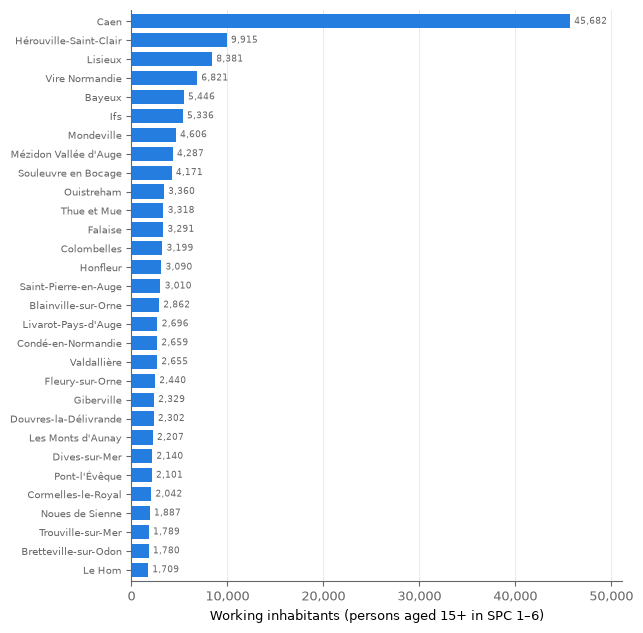

In [4]:
plot_top(df_population, "working_inhabitants", BLUE,
         "Working inhabitants (persons aged 15+ in SPC 1–6)", "working_inhabitants_top30")

saved report\figures\working_inhabitants_all.pdf


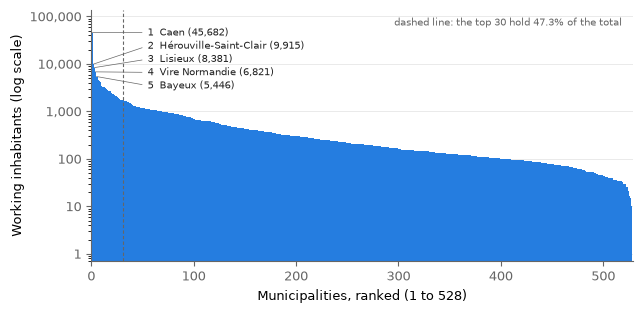

In [5]:
plot_all(df_population, "working_inhabitants", BLUE, "Working inhabitants (log scale)",
         "working_inhabitants_all", share_top_working)

## 2. Employees per municipality (1 point)

### URSSAF data

URSSAF open data "Nombre d'établissements employeurs et effectifs salariés du secteur privé, par commune x APE"
(latest edition, `-last`). One row per municipality × APE code (activity sector) with the number of establishments and
of salaried employees at 31 December of each year 2006–2025. As in the course notebook we use `Code commune` (read as
`str`) and the employees of **2019** (`Effectifs salariés 2019`), the year of the census RP2019, and sum over all APE
sectors.

The CSV export is restricted to the department with the API filter `refine=code_departement:14` (the field
`code_departement`, label "Code département", is listed on the dataset page); the columns are the same as in the full
export. The file is downloaded once; the edition (metadata of the dataset at download time) is saved next to it.

**Scope.** URSSAF counts **private-sector salaried employees at their place of work** (establishments that pay social
contributions to URSSAF). Not included: the public sector (State, local authorities, public hospitals), the
self-employed, farmers and agricultural employees (covered by the MSA), and private households as employers.

In [6]:
if not URSSAF_CSV.exists():
    request = urllib.request.Request(URSSAF_EXPORT_URL, headers={"User-Agent": "Mozilla/5.0 (course project)"})
    with urllib.request.urlopen(request) as response:
        URSSAF_CSV.write_bytes(response.read())
    with urllib.request.urlopen(urllib.request.Request(URSSAF_API, headers={"User-Agent": "Mozilla/5.0"})) as response:
        metas = json.load(response)["metas"]["default"]
    edition = {k: metas.get(k) for k in ["title", "publisher", "modified", "data_processed", "records_count", "license"]}
    edition.update({"downloaded": date.today().isoformat(), "export_url": URSSAF_EXPORT_URL})
    URSSAF_META_JSON.write_text(json.dumps(edition, indent=2, ensure_ascii=False), encoding="utf-8")
    print("downloaded", URSSAF_CSV.relative_to(ROOT))
else:
    print("found", URSSAF_CSV.relative_to(ROOT))
urssaf_edition = json.loads(URSSAF_META_JSON.read_text(encoding="utf-8"))
urssaf_edition

found data\raw\etablissements-et-effectifs-salaries-au-niveau-commune-x-ape-last_dep14.csv


{'title': "Nombre d'établissements employeurs et effectifs salariés du secteur privé, par commune x APE (au 31/12 depuis 2006)",
 'publisher': 'Urssaf',
 'modified': '2026-05-29T05:30:00+00:00',
 'data_processed': '2026-05-29T08:53:51+00:00',
 'records_count': 1227408,
 'license': 'Open Database License (ODbL)',
 'downloaded': '2026-11-27',
 'export_url': 'https://open.urssaf.fr/api/explore/v2.1/catalog/datasets/etablissements-et-effectifs-salaries-au-niveau-commune-x-ape-last/exports/csv?lang=fr&timezone=Europe%2FBerlin&use_labels=true&delimiter=%3B&refine=code_departement%3A14'}

In [7]:
df_urssaf_raw = pd.read_csv(
    URSSAF_CSV, sep=";", encoding="utf-8-sig",
    usecols=["Code département", "Code commune", "Commune", "Code APE", URSSAF_EMPLOYEES],
    dtype={"Code département": str, "Code commune": str, "Code APE": str},
)
print("rows (municipality x APE):", len(df_urssaf_raw))
print("departments:", df_urssaf_raw["Code département"].unique())
assert (df_urssaf_raw["Code département"] == DEPARTMENT).all()
print("duplicated (municipality, APE):", df_urssaf_raw.duplicated(["Code commune", "Code APE"]).sum())
print(f"missing values of '{URSSAF_EMPLOYEES}':", df_urssaf_raw[URSSAF_EMPLOYEES].isna().sum(),
      "| rows with 0:", (df_urssaf_raw[URSSAF_EMPLOYEES] == 0).sum())

# Sum over the APE sectors (missing values count as 0)
df_urssaf = (
    df_urssaf_raw.groupby("Code commune")
    .agg(urssaf_name=("Commune", "first"), employees=(URSSAF_EMPLOYEES, "sum"))
    .rename_axis("urssaf_code").reset_index()
)
urssaf_total = df_urssaf["employees"].sum()
print("URSSAF municipalities:", len(df_urssaf), f"| employees {URSSAF_YEAR}:", urssaf_total)

# Empty 2019 values: is there an establishment in 2019?
establishments = f"Nombre d'établissements {URSSAF_YEAR}"
empty = df_urssaf_raw[URSSAF_EMPLOYEES].isna()
establishments_2019 = pd.read_csv(URSSAF_CSV, sep=";", encoding="utf-8-sig", usecols=[establishments])[establishments]
n_empty_no_establishment = int((empty & establishments_2019.isna()).sum())
n_empty_with_establishment = int((empty & (establishments_2019 > 0)).sum())
print(f"empty {URSSAF_YEAR} employees: {empty.sum()} | without establishment in {URSSAF_YEAR}: "
      f"{n_empty_no_establishment} | with establishment(s): {n_empty_with_establishment}")

rows (municipality x APE): 16301
departments: <ArrowStringArray>
['14']
Length: 1, dtype: str
duplicated (municipality, APE): 0
missing values of 'Effectifs salariés 2019': 7480 | rows with 0: 186
URSSAF municipalities: 516 | employees 2019: 180618.0


empty 2019 employees: 7480 | without establishment in 2019: 7476 | with establishment(s): 4


Empty employee values almost always belong to a municipality × sector row without any establishment in 2019 (the
sector exists in that municipality in other years only); they are 0. The few rows with an establishment but no
employee count are also counted as 0.

### Matching the URSSAF municipalities to the 528 municipalities of 2021

The project uses the municipality geography of 1 January 2021 (IGN CONTOURS-IRIS 2021, the same 528 codes as the
census RP2019). The URSSAF "last" edition uses the **current** geography. The changes between the two are taken from
the official list of changes of municipalities of the INSEE Code officiel géographique (COG 2026, `v_mvt_commune_2026.csv`):
every event after 1 January 2021 that turns one of our 528 municipalities (`TYPECOM_AV = COM`) into another current
municipality (`TYPECOM_AP = COM`), e.g. a merger into a *commune nouvelle* (`MOD` 32) or a change of code because the
chef-lieu moved (`MOD` 50).

Handling: a pure change of code is a relabelling. When several 2021 municipalities were merged into one current
municipality, URSSAF only reports the merged total, and it is **split between the 2021 municipalities in proportion to
their working inhabitants** (an assumption; the split is printed). Municipalities that still have no URSSAF row get
**0 employees**: no private establishment with employees (or values withheld by statistical secrecy).

In [8]:
if not COG_CHANGES_CSV.exists():
    request = urllib.request.Request(COG_CHANGES_URL, headers={"User-Agent": "Mozilla/5.0 (course project)"})
    with urllib.request.urlopen(request) as response:
        COG_CHANGES_CSV.write_bytes(response.read())
    print("downloaded", COG_CHANGES_CSV.relative_to(ROOT))
df_cog = pd.read_csv(COG_CHANGES_CSV, dtype=str)

df_municipalities = gpd.read_file(MUNICIPALITIES_GPKG).sort_values("municipality_id").reset_index(drop=True)
assert list(df_municipalities["municipality_id"]) == list(df_population["municipality_id"])
ours = set(df_municipalities["municipality_id"])

changes = df_cog[
    (df_cog["DATE_EFF"] > GEOGRAPHY_DATE) & (df_cog["TYPECOM_AV"] == "COM") & (df_cog["TYPECOM_AP"] == "COM")
    & df_cog["COM_AV"].isin(ours) & (df_cog["COM_AV"] != df_cog["COM_AP"])
].sort_values("DATE_EFF")
display(changes[["MOD", "DATE_EFF", "COM_AV", "LIBELLE_AV", "COM_AP", "LIBELLE_AP"]])

# 2021 code -> current code (follow successive changes)
to_current = dict(zip(changes["COM_AV"], changes["COM_AP"]))
def current_code(code):
    while code in to_current:
        code = to_current[code]
    return code

df_match = df_population[["municipality_id", "name", "working_inhabitants", "P19_POP"]].copy()
df_match["urssaf_code"] = df_match["municipality_id"].map(current_code)

print("URSSAF codes before recoding: not among our 528:", sorted(set(df_urssaf["urssaf_code"]) - ours),
      "| our municipalities without URSSAF row:", len(ours - set(df_urssaf["urssaf_code"])))
unmatched_urssaf = sorted(set(df_urssaf["urssaf_code"]) - set(df_match["urssaf_code"]))
print("URSSAF codes not matched after recoding:", unmatched_urssaf)
assert not unmatched_urssaf

# Split merged URSSAF totals by working inhabitants
df_match = df_match.merge(df_urssaf, on="urssaf_code", how="left", validate="m:1")
df_match["has_urssaf_row"] = df_match["employees"].notna()
group_working = df_match.groupby("urssaf_code")["working_inhabitants"].transform("sum")
df_match["n_in_group"] = df_match.groupby("urssaf_code")["municipality_id"].transform("size")
df_match["split_share"] = np.where(df_match["n_in_group"] > 1, df_match["working_inhabitants"] / group_working, 1.0)
df_match["employees_urssaf_code"] = df_match["employees"]
df_match["employees"] = (df_match["employees"] * df_match["split_share"]).fillna(0.0)

recoded = df_match[df_match["urssaf_code"] != df_match["municipality_id"]]
merged_groups = df_match[df_match["n_in_group"] > 1]
print("\nrecoded / merged municipalities:")
display(df_match[df_match["urssaf_code"].isin(recoded["urssaf_code"])][
    ["municipality_id", "name", "urssaf_code", "urssaf_name", "employees_urssaf_code", "working_inhabitants",
     "split_share", "employees"]])

no_row = df_match[~df_match["has_urssaf_row"]]
print(f"municipalities without URSSAF row -> 0 employees: {len(no_row)} "
      f"(population {no_row['P19_POP'].sum():.0f}, max {no_row['P19_POP'].max():.0f})")
display(no_row[["municipality_id", "name", "P19_POP", "working_inhabitants"]])

employees_total = df_match["employees"].sum()
print(f"employees over the 528 municipalities: {employees_total} (URSSAF department total {urssaf_total})")
assert np.isclose(employees_total, urssaf_total)

,MOD,DATE_EFF,COM_AV,LIBELLE_AV,COM_AP,LIBELLE_AP
297,50,2024-04-24,14011,Aurseulles,14581,Aurseulles
74,32,2025-01-01,14300,Gerrots,14743,Victot-en-Auge
77,32,2025-01-01,14623,Saint-Martin-de-Fontenay,14408,Saint-Martin-de-May


URSSAF codes before recoding: not among our 528: ['14581'] | our municipalities without URSSAF row: 13
URSSAF codes not matched after recoding: []

recoded / merged municipalities:


,municipality_id,name,urssaf_code,urssaf_name,employees_urssaf_code,working_inhabitants,split_share,employees
6,14011,Aurseulles,14581,14581 Aurseulles,31.0,980.283120,1.000000,31.000000
214,14300,Gerrots,14743,14743 Victot-en-Auge,12.0,15.294118,0.304094,3.649123
295,14408,May-sur-Orne,14408,14408 Saint-Martin-de-May,406.0,1010.573847,0.481888,195.646570
429,14623,Saint-Martin-de-Fontenay,14408,14408 Saint-Martin-de-May,406.0,1086.539239,0.518112,210.353430
511,14743,Victot-Pontfol,14743,14743 Victot-en-Auge,12.0,35.000000,0.695906,8.350877


municipalities without URSSAF row -> 0 employees: 10 (population 942, max 216)


,municipality_id,name,P19_POP,working_inhabitants
32,14043,Barou-en-Auge,70.0,30.000000
63,14087,Bonnœil,125.0,44.642857
99,14136,Cardonville,101.0,36.822917
245,14343,Les Isles-Bardel,66.0,26.190476
250,14348,Juvigny-sur-Seulles,81.0,30.000000
258,14360,Leffard,216.0,105.882353
347,14496,Périgny,57.0,39.310345
359,14512,Pontécoulant,73.0,26.071429
371,14531,Rapilly,48.0,10.212766
486,14710,Tréprel,105.0,53.472222


employees over the 528 municipalities: 180618.0 (URSSAF department total 180618.0)


In [9]:
df_population = df_population.merge(df_match[["municipality_id", "employees"]], on="municipality_id", validate="1:1")
caen_employees = df_population.set_index("municipality_id").loc["14118", "employees"]
top_employees = df_population.nlargest(TOP_N, "employees")
share_top_employees = top_employees["employees"].sum() / employees_total
print(f"Caen: {caen_employees} ({caen_employees / employees_total:.4%}) | top {TOP_N}: {share_top_employees:.4%}")
print("municipalities with 0 employees:", (df_population["employees"] == 0).sum(),
      "| median:", df_population["employees"].median())
top_employees[["municipality_id", "name", "working_inhabitants", "employees"]].head(10)

Caen: 35246.0 (19.5141%) | top 30: 75.5246%
municipalities with 0 employees: 55 | median: 16.0


,municipality_id,name,working_inhabitants,employees
84,14118,Caen,45682.401965,35246.0
233,14327,Hérouville-Saint-Clair,9915.146215,11118.0
310,14437,Mondeville,4606.112639,10500.0
526,14762,Vire Normandie,6820.974677,8968.0
262,14366,Lisieux,8381.228180,8278.0
243,14341,Ifs,5335.659593,4922.0
36,14047,Bayeux,5446.063998,4575.0
117,14167,Colombelles,3198.727633,4482.0
100,14137,Carpiquet,1495.000000,3824.0
237,14333,Honfleur,3090.000000,3591.0


saved report\figures\employees_top30.pdf


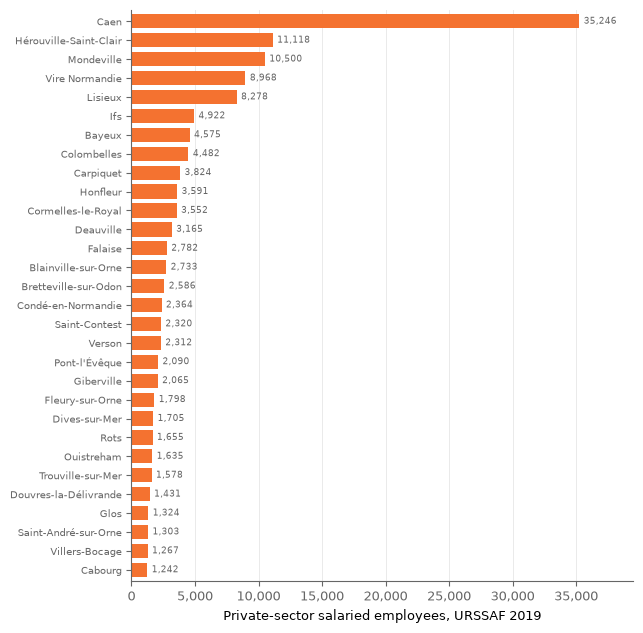

In [10]:
plot_top(df_population, "employees", ORANGE, f"Private-sector salaried employees, URSSAF {URSSAF_YEAR}",
         "employees_top30")

saved report\figures\employees_all.pdf


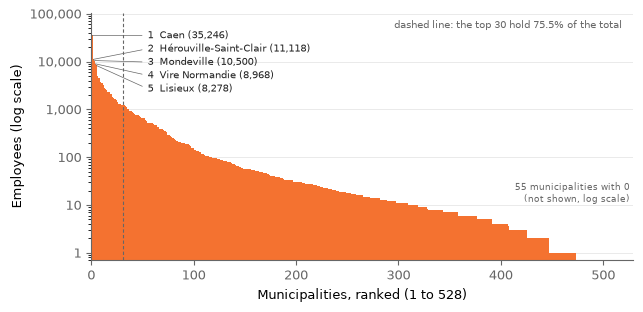

In [11]:
plot_all(df_population, "employees", ORANGE, "Employees (log scale)", "employees_all", share_top_employees)

## 3. Difference between working inhabitants and employees (1 point)

For each municipality, $\Delta_i = W^{\text{res}}_i - E_i$ (working inhabitants minus URSSAF employees).
$\Delta_i > 0$: more working residents than jobs, residents commute out (**net outflow**); $\Delta_i < 0$: more jobs
than working residents (**net inflow** of employees).

**Comparability.** The two totals differ a lot because the definitions differ: the census counts all residents of
working SPC (public sector, self-employed, farmers, unemployed with a former occupation; place of residence), URSSAF
only private salaried employees (place of work). As an additional view, employees are scaled to the total of
working inhabitants, $\tilde E_i = E_i \cdot \sum_k W^{\text{res}}_k / \sum_k E_k$; $\tilde\Delta_i = W^{\text{res}}_i
- \tilde E_i$ sums to 0 and shows the relative pattern. This is also how employment enters Ex. 2.2 (attraction
proportional to employment).

In [12]:
scale_factor = working_total / employees_total
df_population["difference"] = df_population["working_inhabitants"] - df_population["employees"]
df_population["employees_scaled"] = df_population["employees"] * scale_factor
df_population["difference_scaled"] = df_population["working_inhabitants"] - df_population["employees_scaled"]

print(f"working inhabitants: {working_total} | employees: {employees_total}")
print(f"ratio employees / working inhabitants: {employees_total / working_total} | scale factor: {scale_factor}")
print(f"ratio employees / employed persons 15+ (detailed census): {employees_total / employed_15p}")
print(f"sum of differences: {df_population['difference'].sum()} | scaled: {df_population['difference_scaled'].sum()}")
for col in ["difference", "difference_scaled"]:
    print(f"{col}: outflow (> 0) {(df_population[col] > 0).sum()}, inflow (< 0) {(df_population[col] < 0).sum()}, "
          f"zero {(df_population[col] == 0).sum()}")

show = ["municipality_id", "name", "working_inhabitants", "employees", "difference",
        "employees_scaled", "difference_scaled"]
extremes = {}
for col in ["difference", "difference_scaled"]:
    outflow = df_population.nlargest(N_TABLE, col)
    inflow = df_population.nsmallest(N_TABLE, col)
    extremes[col] = {"outflow": outflow, "inflow": inflow}
    print(f"\n{col}: largest net outflow")
    display(outflow[show])
    print(f"{col}: largest net inflow")
    display(inflow[show])

working inhabitants: 311885.64777839184 | employees: 180618.0
ratio employees / working inhabitants: 0.5791161000404125 | scale factor: 1.726769468039685
ratio employees / employed persons 15+ (detailed census): 0.6517423485039116
sum of differences: 131267.64777839187 | scaled: 3.637978807091713e-11
difference: outflow (> 0) 505, inflow (< 0) 23, zero 0
difference_scaled: outflow (> 0) 469, inflow (< 0) 59, zero 0

difference: largest net outflow


,municipality_id,name,working_inhabitants,employees,difference,employees_scaled,difference_scaled
84,14118,Caen,45682.401965,35246.0,10436.401965,60861.716671,-15179.314705
45,14061,Souleuvre en Bocage,4171.220922,660.0,3511.220922,1139.667849,3031.553073
307,14431,Mézidon Vallée d'Auge,4287.367215,853.0,3434.367215,1472.934356,2814.432859
72,14098,Thue et Mue,3317.901945,907.0,2410.901945,1566.179908,1751.722037
498,14726,Valdallière,2655.000000,492.0,2163.000000,849.570578,1805.429422


difference: largest net inflow


,municipality_id,name,working_inhabitants,employees,difference,employees_scaled,difference_scaled
310,14437,Mondeville,4606.112639,10500.0,-5893.887361,18131.079414,-13524.966775
100,14137,Carpiquet,1495.000000,3824.0,-2329.000000,6603.166446,-5108.166446
526,14762,Vire Normandie,6820.974677,8968.0,-2147.025323,15485.668589,-8664.693913
153,14220,Deauville,1283.442854,3165.0,-1881.557146,5465.225366,-4181.782513
128,14181,Cormelles-le-Royal,2042.379954,3552.0,-1509.620046,6133.485150,-4091.105196



difference_scaled: largest net outflow


,municipality_id,name,working_inhabitants,employees,difference,employees_scaled,difference_scaled
45,14061,Souleuvre en Bocage,4171.220922,660.0,3511.220922,1139.667849,3031.553073
307,14431,Mézidon Vallée d'Auge,4287.367215,853.0,3434.367215,1472.934356,2814.432859
498,14726,Valdallière,2655.000000,492.0,2163.000000,849.570578,1805.429422
72,14098,Thue et Mue,3317.901945,907.0,2410.901945,1566.179908,1751.722037
19,14027,Les Monts d'Aunay,2206.605985,374.0,1832.605985,645.811781,1560.794204


difference_scaled: largest net inflow


,municipality_id,name,working_inhabitants,employees,difference,employees_scaled,difference_scaled
84,14118,Caen,45682.401965,35246.0,10436.401965,60861.716671,-15179.314705
310,14437,Mondeville,4606.112639,10500.0,-5893.887361,18131.079414,-13524.966775
233,14327,Hérouville-Saint-Clair,9915.146215,11118.0,-1202.853785,19198.222946,-9283.076730
526,14762,Vire Normandie,6820.974677,8968.0,-2147.025323,15485.668589,-8664.693913
262,14366,Lisieux,8381.228180,8278.0,103.228180,14294.197656,-5912.969476


saved report\figures\inhabitants_minus_employees_map.pdf | colour limits ± 10436.401965305522


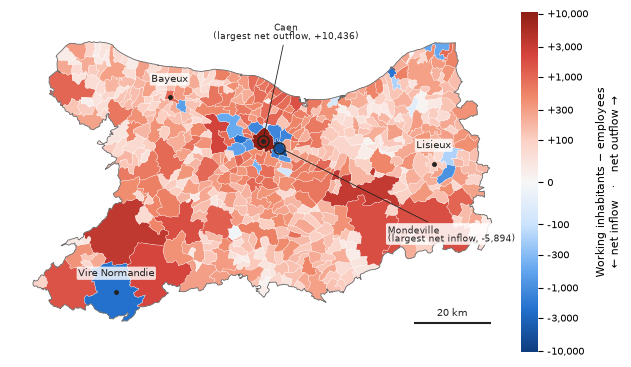

In [13]:
def difference_map(column, name, title_note):
    df_map = df_municipalities.merge(df_population[["municipality_id", column]], on="municipality_id", validate="1:1")
    assert df_map[column].notna().all()
    limit = df_map[column].abs().max()
    norm = SymLogNorm(linthresh=SYMLOG_LINTHRESH, linscale=0.6, vmin=-limit, vmax=limit, base=10)

    fig, ax = plt.subplots(figsize=(6.5, 4.8))
    df_map.plot(ax=ax, column=column, cmap=DIVERGING, norm=norm, edgecolor="white", linewidth=0.2, rasterized=True)
    df_map.dissolve().boundary.plot(ax=ax, color=TEXT_2, linewidth=0.6)

    out_id = df_population.loc[df_population[column].idxmax(), "municipality_id"]
    in_id = df_population.loc[df_population[column].idxmin(), "municipality_id"]
    points = df_map.set_index("municipality_id").geometry.representative_point()
    marked = {out_id: "largest net outflow", in_id: "largest net inflow"}
    for mid, row in df_map.set_index("municipality_id").loc[list(TOWNS)].iterrows():
        p = points[mid]
        ax.plot(p.x, p.y, "o", color=TEXT, markersize=2.5, zorder=3)
        if mid in marked:
            continue
        ax.text(p.x, p.y + 4000, row["name"], fontsize=7, color=TEXT, ha="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8), zorder=4)
    for mid, kind in marked.items():
        p = points[mid]
        value = df_population.set_index("municipality_id").loc[mid, column]
        ax.plot(p.x, p.y, "o", markerfacecolor="none", markeredgecolor=TEXT, markersize=8, mew=1.0, zorder=3)
        dx, dy, ha, va = MARK_OFFSETS[name][kind]
        ax.annotate(f"{df_population.set_index('municipality_id').loc[mid, 'name']}\n({kind}, {value:+,.0f})",
                    xy=(p.x, p.y), xytext=(p.x + dx, p.y + dy), fontsize=6.5, color=TEXT, ha=ha, va=va,
                    linespacing=1.0, arrowprops=dict(arrowstyle="-", color=TEXT, lw=0.6, shrinkB=4),
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85), zorder=5)

    style_map_axes(ax)
    scale_bar(ax, 20_000, "20 km", x_frac=0.80, y_frac=0.04)
    sm = mpl.cm.ScalarMappable(cmap=DIVERGING, norm=norm)
    cbar = fig.colorbar(sm, ax=ax, shrink=0.75, pad=0.01)
    ticks = [t for t in [-30000, -10000, -3000, -1000, -300, -100, 0, 100, 300, 1000, 3000, 10000, 30000]
             if abs(t) <= limit]
    cbar.set_ticks(ticks)
    cbar.set_ticklabels([f"{t:+,}" if t else "0" for t in ticks])
    cbar.ax.tick_params(labelsize=7)
    cbar.set_label(f"{title_note}\n← net inflow   ·   net outflow →", fontsize=8)
    cbar.outline.set_visible(False)
    fig.tight_layout()
    path = save_figure(fig, name, preview_png=True)
    print("saved", path.relative_to(ROOT), "| colour limits ±", limit)
    plt.show()
    return out_id, in_id


# label offsets (m) of the two marked municipalities, set by eye on the PNG previews
MARK_OFFSETS = {
    "inhabitants_minus_employees_map": {"largest net outflow": (6000, 26000, "center", "bottom"),
                                        "largest net inflow": (28000, -20000, "left", "top")},
    "inhabitants_minus_employees_scaled_map": {"largest net outflow": (-15000, 14000, "center", "bottom"),
                                               "largest net inflow": (22000, -14000, "left", "top")},
}
raw_extremes = difference_map("difference", "inhabitants_minus_employees_map",
                              "Working inhabitants − employees")

saved report\figures\inhabitants_minus_employees_scaled_map.pdf | colour limits ± 15179.314705221215


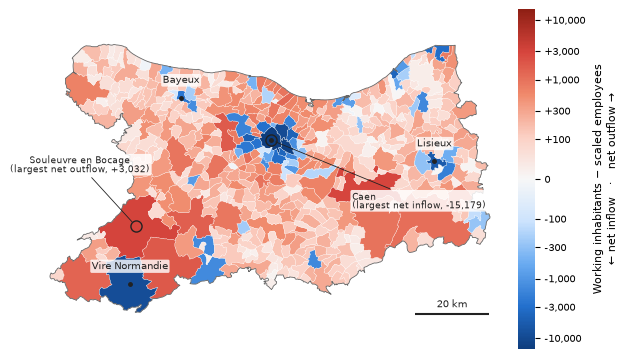

In [14]:
scaled_extremes = difference_map("difference_scaled", "inhabitants_minus_employees_scaled_map",
                                 "Working inhabitants − scaled employees")

**Reading of the two maps.** In the raw view, 505 of 528 municipalities have more working inhabitants than URSSAF
employees, simply because URSSAF counts only 58 % as many persons. Caen has the largest positive difference: its
working residents are compared with private jobs only, while Caen concentrates the public-sector jobs (university,
CHU, administrations) that URSSAF does not cover. The largest net inflow is Mondeville (commercial and industrial
zones east of Caen). After scaling, Caen becomes the largest net inflow and the largest outflows are large rural
*communes nouvelles* without an employment centre (Souleuvre en Bocage, Mézidon Vallée d'Auge).

**Municipalities that change side** between the raw and the scaled view. Scaling multiplies the employees by a factor
> 1, so a municipality can only move from outflow to inflow.

In [15]:
side_raw = np.sign(df_population["difference"])
side_scaled = np.sign(df_population["difference_scaled"])
df_changed = df_population[side_raw != side_scaled].sort_values("working_inhabitants", ascending=False)
print("municipalities changing side:", len(df_changed),
      "| outflow -> inflow:", ((side_raw > 0) & (side_scaled < 0)).sum(),
      "| inflow -> outflow:", ((side_raw < 0) & (side_scaled > 0)).sum())
print(f"working inhabitants in these municipalities: {df_changed['working_inhabitants'].sum()} "
      f"({df_changed['working_inhabitants'].sum() / working_total:.4%})")
df_changed[show]

municipalities changing side: 36 | outflow -> inflow: 36 | inflow -> outflow: 0
working inhabitants in these municipalities: 105110.66179229105 (33.7017%)


,municipality_id,name,working_inhabitants,employees,difference,employees_scaled,difference_scaled
84,14118,Caen,45682.401965,35246.0,10436.401965,60861.716671,-15179.314705
262,14366,Lisieux,8381.228180,8278.0,103.228180,14294.197656,-5912.969476
36,14047,Bayeux,5446.063998,4575.0,871.063998,7899.970316,-2453.906318
243,14341,Ifs,5335.659593,4922.0,413.659593,8499.159322,-3163.499729
184,14258,Falaise,3290.569377,2782.0,508.569377,4803.872660,-1513.303283
53,14076,Blainville-sur-Orne,2861.868845,2733.0,128.868845,4719.260956,-1857.392111
123,14174,Condé-en-Normandie,2659.009283,2364.0,295.009283,4082.083022,-1423.073739
190,14271,Fleury-sur-Orne,2440.011153,1798.0,642.011153,3104.731504,-664.720351
215,14301,Giberville,2328.814593,2065.0,263.814593,3565.778952,-1236.964359
160,14228,Douvres-la-Délivrande,2302.053875,1431.0,871.053875,2471.007109,-168.953233


## Results for later exercises and for the report

In [16]:
df_employment = df_population[["municipality_id", "name", "working_inhabitants", "employees", "difference"]].copy()
df_employment = df_employment.sort_values("municipality_id").reset_index(drop=True)
assert len(df_employment) == 528 and df_employment["municipality_id"].is_unique
assert list(df_employment["municipality_id"]) == list(df_municipalities["municipality_id"])
df_employment.to_parquet(EMPLOYMENT_PARQUET)
print("saved", EMPLOYMENT_PARQUET.relative_to(ROOT), df_employment.shape)


def records(df, columns):
    return {str(r["municipality_id"]): {c: (r[c].item() if hasattr(r[c], "item") else r[c]) for c in columns}
            for _, r in df.iterrows()}


cols = ["name", "working_inhabitants", "employees", "difference", "employees_scaled", "difference_scaled"]
results = {
    "working_inhabitants": {
        "definition": "C19_POP15P_CS1 + ... + C19_POP15P_CS6 (persons aged 15+ in SPC 1-6, aggregated census RP2019)",
        "total": float(working_total),
        "population_15p": float(pop15_total),
        "population": float(population_total),
        "share_of_15p": float(working_total / pop15_total),
        "share_of_population": float(working_total / population_total),
        "spc_totals": {k: float(v) for k, v in spc_totals.items()},
        "detailed_census_spc1_6_15p": float(working_detailed),
        "activity_check": {
            "source": "detailed census RP2019, AGEREV >= 15, weights IPONDI, CS1 x TACT",
            "spc1_6_persons": float(working_activity_total),
            "spc1_6_by_activity": {k: float(v) for k, v in working_by_activity.items()},
            "spc1_6_share_by_activity": {k: float(v) for k, v in working_activity_shares.items()},
            "share_employed": float(share_working_employed),
            "share_unemployed": float(share_working_unemployed),
            "share_other": float(other_statuses.sum()),
            "employed_15p": float(employed_15p),
            "employed_15p_in_spc1_6": float(employed_15p_in_working_spc),
            "employed_15p_in_spc7_8": float(employed_15p_outside_working_spc),
            "ratio_working_inhabitants_to_employed_15p": float(working_total / employed_15p),
            "crosstab_persons": {str(k): {c: float(v) for c, v in row.items()}
                                 for k, row in df_spc_activity.to_dict("index").items()},
        },
        "caen": float(caen_working),
        "caen_share": float(caen_working / working_total),
        "top_n": TOP_N,
        "top_n_share": float(share_top_working),
        "median": float(df_population["working_inhabitants"].median()),
        "top10": records(top_working.head(10), ["name", "working_inhabitants"]),
    },
    "employees": {
        "source": urssaf_edition,
        "year": URSSAF_YEAR,
        "n_rows": int(len(df_urssaf_raw)),
        "n_missing_values": int(df_urssaf_raw[URSSAF_EMPLOYEES].isna().sum()),
        "n_missing_without_establishment": n_empty_no_establishment,
        "n_missing_with_establishment": n_empty_with_establishment,
        "n_zero_with_urssaf_row": int(((df_population["employees"] == 0)
                                       & df_population["municipality_id"].isin(df_match.loc[df_match["has_urssaf_row"],
                                                                                          "municipality_id"])).sum()),
        "n_urssaf_municipalities": int(len(df_urssaf)),
        "total": float(urssaf_total),
        "total_528": float(employees_total),
        "urssaf_codes_not_in_528_before_recoding": sorted(set(df_urssaf["urssaf_code"]) - ours),
        "cog_changes": changes[["MOD", "DATE_EFF", "COM_AV", "LIBELLE_AV", "COM_AP", "LIBELLE_AP"]].to_dict("records"),
        "recoded": records(df_match[df_match["urssaf_code"].isin(recoded["urssaf_code"])],
                           ["name", "urssaf_code", "urssaf_name", "employees_urssaf_code", "working_inhabitants",
                            "split_share", "employees"]),
        "no_urssaf_row": records(no_row, ["name", "P19_POP", "working_inhabitants"]),
        "n_zero": int((df_population["employees"] == 0).sum()),
        "caen": float(caen_employees),
        "caen_share": float(caen_employees / employees_total),
        "top_n_share": float(share_top_employees),
        "median": float(df_population["employees"].median()),
        "top10": records(top_employees.head(10), ["name", "employees"]),
    },
    "difference": {
        "ratio_employees_to_working": float(employees_total / working_total),
        "ratio_employees_to_employed_15p": float(employees_total / employed_15p),
        "scale_factor": float(scale_factor),
        "symlog_linthresh": SYMLOG_LINTHRESH,
        "n_outflow": int((df_population["difference"] > 0).sum()),
        "n_inflow": int((df_population["difference"] < 0).sum()),
        "n_outflow_scaled": int((df_population["difference_scaled"] > 0).sum()),
        "n_inflow_scaled": int((df_population["difference_scaled"] < 0).sum()),
        "largest_outflow": raw_extremes[0],
        "largest_inflow": raw_extremes[1],
        "largest_outflow_scaled": scaled_extremes[0],
        "largest_inflow_scaled": scaled_extremes[1],
        "top_outflow": records(extremes["difference"]["outflow"], cols),
        "top_inflow": records(extremes["difference"]["inflow"], cols),
        "top_outflow_scaled": records(extremes["difference_scaled"]["outflow"], cols),
        "top_inflow_scaled": records(extremes["difference_scaled"]["inflow"], cols),
        "n_changed_side": int(len(df_changed)),
        "changed_side_working_share": float(df_changed["working_inhabitants"].sum() / working_total),
        "changed_side": records(df_changed, cols),
        "towns": records(df_population[df_population["municipality_id"].isin(TOWNS)], cols),
    },
}
RESULTS_JSON.write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding="utf-8")
print("saved", RESULTS_JSON.relative_to(ROOT))
{k: results["difference"][k] for k in ["ratio_employees_to_working", "largest_outflow", "largest_inflow",
                                        "largest_outflow_scaled", "largest_inflow_scaled", "n_changed_side"]}

saved data\processed\employment_14.parquet (528, 5)
saved data\processed\ex13_results.json


{'ratio_employees_to_working': 0.5791161000404125,
 'largest_outflow': '14118',
 'largest_inflow': '14437',
 'largest_outflow_scaled': '14061',
 'largest_inflow_scaled': '14118',
 'n_changed_side': 36}

## Validation with commuting data (MOBPRO)

The difference of Section 3 compares two sources with different definitions: URSSAF counts only private salaried
jobs (58 % of the census count), so the raw difference is positive almost everywhere. INSEE's commuting file
**MOBPRO RP2019** ("Mobilités professionnelles des individus : déplacements commune de résidence / commune de
travail", insee.fr/fr/statistiques/6456056) gives, for every employed person of the census, the municipality of
residence (`COMMUNE`, `ARM` for the arrondissements of Paris, Lyon, Marseille) and the municipality of work (`DCLT`),
with the weight `IPONDI`. It covers **all** jobs (public sector, self-employed and farmers included), with the same year
(2019) and geography (2021) as our census. It is therefore the real-data reference for the net commuting balance.

This section is a **validation only**: the answers of Ex. 1.3 stay those based on the census and URSSAF, as the
exercise asks. For each of the 528 municipalities $i$ (weighted with `IPONDI`):

- `employed_residents_mobpro` $R_i$: employed persons living in $i$ (`COMMUNE` $= i$, any `DCLT`);
- `jobs_mobpro` $J_i$: persons working in $i$ (`DCLT` $= i$, any `COMMUNE`, also residents of other departments);
- `net_mobpro` $N_i = R_i - J_i$ ($> 0$ net outflow, $< 0$ net inflow), comparable with $\Delta_i$ and $\tilde\Delta_i$.

The file (France, about 790 MB) is read in chunks with the columns and dtypes of the course notebook; we keep the rows
where `COMMUNE` **or** `DCLT` is in the department, so that commuters from and to other departments are included.

In [17]:
if not MOBPRO_CSV.exists():
    zip_path = DATA_RAW / "RP2019_mobpro_csv.zip"
    request = urllib.request.Request(MOBPRO_URL, headers={"User-Agent": "Mozilla/5.0 (course project)"})
    with urllib.request.urlopen(request) as response, open(zip_path, "wb") as f:
        shutil.copyfileobj(response, f)
    with zipfile.ZipFile(zip_path) as archive:
        archive.extract(MOBPRO_CSV.name, DATA_RAW)
        archive.extract(MOBPRO_VARMOD.name, DATA_RAW)
    zip_path.unlink()
    print("downloaded", MOBPRO_CSV.relative_to(ROOT))
else:
    print("found", MOBPRO_CSV.relative_to(ROOT))

found data\raw\FD_MOBPRO_2019.csv


In [18]:
chunks = []
n_rows_france, weight_france = 0, 0.0
for chunk in pd.read_csv(MOBPRO_CSV, sep=";", usecols=list(MOBPRO_COLUMNS), dtype=MOBPRO_COLUMNS,
                         chunksize=MOBPRO_CHUNKSIZE):
    n_rows_france += len(chunk)
    weight_france += chunk["IPONDI"].sum()
    # Paris, Lyon, Marseille: the arrondissement of residence is in ARM (as in the course notebook)
    f = chunk["ARM"] != "ZZZZZ"
    chunk.loc[f, "COMMUNE"] = chunk.loc[f, "ARM"]
    keep = (chunk["COMMUNE"].str[:2] == DEPARTMENT) | (chunk["DCLT"].str[:2] == DEPARTMENT)
    chunks.append(chunk[keep])
df_mobpro = pd.concat(chunks, ignore_index=True).rename(columns={
    "COMMUNE": "origin_id", "DCLT": "destination_id", "IPONDI": "weight", "TRANS": "transport_mode"
})[["origin_id", "destination_id", "weight", "transport_mode"]]
del chunks

lives_in = df_mobpro["origin_id"].str[:2] == DEPARTMENT
works_in = df_mobpro["destination_id"].str[:2] == DEPARTMENT
print(f"MOBPRO France: {n_rows_france:,} rows, {weight_france:,.0f} employed persons")
print(f"kept (living or working in {DEPARTMENT}): {len(df_mobpro):,} rows, {df_mobpro['weight'].sum():,.0f} persons")
print(f"  living in {DEPARTMENT}: {lives_in.sum():,} rows | working in {DEPARTMENT}: {works_in.sum():,} rows "
      f"| both: {(lives_in & works_in).sum():,} rows")

MOBPRO France: 7,931,862 rows, 27,154,874 employed persons
kept (living or working in 14): 72,405 rows, 297,790 persons
  living in 14: 67,496 rows | working in 14: 67,099 rows | both: 62,190 rows


**Municipality codes.** MOBPRO RP2019 is published in the geography of 1 January 2021, like our census and
IGN CONTOURS-IRIS 2021. Check: every code of the department in `COMMUNE` and `DCLT` must be one of our 528, and every
one of our municipalities should appear.

In [19]:
origins_dep = set(df_mobpro.loc[lives_in, "origin_id"])
destinations_dep = set(df_mobpro.loc[works_in, "destination_id"])
codes_not_ours = sorted((origins_dep | destinations_dep) - ours)
ours_without_residents = sorted(ours - origins_dep)
ours_without_jobs = sorted(ours - destinations_dep)
print("department codes in MOBPRO:", len(origins_dep), "(residence),", len(destinations_dep), "(work)")
print("codes not among our 528:", codes_not_ours)
print("our municipalities without employed resident in MOBPRO:", ours_without_residents)
print("our municipalities without job in MOBPRO:", len(ours_without_jobs), ours_without_jobs[:20])
assert not codes_not_ours

department codes in MOBPRO: 528 (residence), 521 (work)
codes not among our 528: []
our municipalities without employed resident in MOBPRO: []
our municipalities without job in MOBPRO: 7 ['14043', '14285', '14300', '14329', '14448', '14496', '14531']


In [20]:
employed_residents_by_code = df_mobpro[lives_in].groupby("origin_id")["weight"].sum()
jobs_by_code = df_mobpro[works_in].groupby("destination_id")["weight"].sum()
df_population["employed_residents_mobpro"] = df_population["municipality_id"].map(employed_residents_by_code).fillna(0.0)
df_population["jobs_mobpro"] = df_population["municipality_id"].map(jobs_by_code).fillna(0.0)
df_population["net_mobpro"] = df_population["employed_residents_mobpro"] - df_population["jobs_mobpro"]

same_municipality = lives_in & (df_mobpro["origin_id"] == df_mobpro["destination_id"])
mobpro_totals = {
    "employed_residents": df_mobpro.loc[lives_in, "weight"].sum(),
    "jobs": df_mobpro.loc[works_in, "weight"].sum(),
    "living_and_working_in_department": df_mobpro.loc[lives_in & works_in, "weight"].sum(),
    "living_in_working_outside": df_mobpro.loc[lives_in & ~works_in, "weight"].sum(),
    "living_outside_working_in": df_mobpro.loc[~lives_in & works_in, "weight"].sum(),
    "working_in_own_municipality": df_mobpro.loc[same_municipality, "weight"].sum(),
}
mobpro_totals["net_department"] = mobpro_totals["employed_residents"] - mobpro_totals["jobs"]
mobpro_shares = {
    "working_in_own_municipality": mobpro_totals["working_in_own_municipality"] / mobpro_totals["employed_residents"],
    "residents_working_outside": mobpro_totals["living_in_working_outside"] / mobpro_totals["employed_residents"],
    "jobs_held_by_outside_residents": mobpro_totals["living_outside_working_in"] / mobpro_totals["jobs"],
}
assert np.isclose(df_population["employed_residents_mobpro"].sum(), mobpro_totals["employed_residents"])
assert np.isclose(df_population["jobs_mobpro"].sum(), mobpro_totals["jobs"])
assert np.isclose(mobpro_totals["employed_residents"],
                  mobpro_totals["living_and_working_in_department"] + mobpro_totals["living_in_working_outside"])
display(pd.Series(mobpro_totals, name="persons").round(0).to_frame())
display(pd.Series(mobpro_shares, name="share").to_frame())

# Where the residents working outside work, and where the persons working in the department live
# (first two characters of the code: department; 99 = abroad)
outside_work = (df_mobpro[lives_in & ~works_in].groupby(df_mobpro["destination_id"].str[:2])["weight"].sum()
                .sort_values(ascending=False))
outside_home = (df_mobpro[~lives_in & works_in].groupby(df_mobpro["origin_id"].str[:2])["weight"].sum()
                .sort_values(ascending=False))
display(pd.DataFrame({"department of work (residents working outside)": outside_work.head(6).round(0)}))
display(pd.DataFrame({"department of residence (persons working in from outside)": outside_home.head(6).round(0)}))
print("working abroad (DCLT 99999):", df_mobpro.loc[lives_in & (df_mobpro["destination_id"] == MOBPRO_ABROAD), "weight"].sum())

,persons
employed_residents,277131.0
jobs,275908.0
living_and_working_in_department,255249.0
living_in_working_outside,21882.0
living_outside_working_in,20659.0
working_in_own_municipality,83263.0
net_department,1223.0


,share
working_in_own_municipality,0.300445
residents_working_outside,0.078959
jobs_held_by_outside_residents,0.074876


,department of work (residents working outside)
destination_id,
50,5602.0
61,4564.0
76,2712.0
27,2005.0
75,1784.0
92,711.0


,department of residence (persons working in from outside)
origin_id,
50,6126.0
27,4960.0
61,4674.0
76,1452.0
35,291.0
75,241.0


working abroad (DCLT 99999): 219.0508040942935


### Employed residents: MOBPRO vs. census

MOBPRO counts the employed persons of the census at their place of residence. Its department total should be close
to the employed persons aged 15+ of the detailed census (`TACT` = 11, Section 1) and below the working inhabitants
(SPC 1–6, which also contain the unemployed with a former occupation).

In [21]:
employed_mobpro_total = mobpro_totals["employed_residents"]
print(f"MOBPRO employed residents:              {employed_mobpro_total:,.1f}")
print(f"detailed census, employed 15+ (TACT 11): {employed_15p:,.1f} "
      f"(difference {employed_mobpro_total - employed_15p:+,.1f}, {employed_mobpro_total / employed_15p - 1:+.4%})")
print(f"working inhabitants (SPC 1-6):          {working_total:,.1f} "
      f"(ratio working inhabitants / MOBPRO {working_total / employed_mobpro_total:.4f})")

ratio_working_to_mobpro = df_population["working_inhabitants"] / df_population["employed_residents_mobpro"]
pearson_residents = df_population["working_inhabitants"].corr(df_population["employed_residents_mobpro"])
print(f"per municipality: Pearson r(working inhabitants, MOBPRO employed residents) = {pearson_residents:.4f}")
print("ratio working inhabitants / MOBPRO employed residents over the municipalities:")
display(ratio_working_to_mobpro.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).to_frame("ratio").T)

MOBPRO employed residents:              277,131.0
detailed census, employed 15+ (TACT 11): 277,131.0 (difference +0.0, +0.0000%)
working inhabitants (SPC 1-6):          311,885.6 (ratio working inhabitants / MOBPRO 1.1254)
per municipality: Pearson r(working inhabitants, MOBPRO employed residents) = 0.9997
ratio working inhabitants / MOBPRO employed residents over the municipalities:


,count,mean,std,min,5%,25%,50%,75%,95%,max
ratio,528.0,1.096848,0.076501,1.0,1.0,1.052632,1.088725,1.128624,1.207878,1.8


### Jobs: MOBPRO vs. URSSAF

MOBPRO counts all jobs at the place of work (persons working in the municipality, wherever they live). URSSAF covers
only private salaried jobs. The coverage ratio URSSAF / MOBPRO shows where URSSAF misses jobs, and the absolute
gap $J_i - E_i$ where it misses most.

In [22]:
jobs_mobpro_total = mobpro_totals["jobs"]
coverage_total = employees_total / jobs_mobpro_total
print(f"MOBPRO jobs in {DEPARTMENT}: {jobs_mobpro_total:,.1f} | URSSAF employees: {employees_total:,.1f} "
      f"| coverage URSSAF / MOBPRO: {coverage_total:.4f}")

df_population["jobs_missed_urssaf"] = df_population["jobs_mobpro"] - df_population["employees"]
df_population["coverage_urssaf"] = df_population["employees"] / df_population["jobs_mobpro"].where(
    df_population["jobs_mobpro"] > 0)
pearson_jobs = df_population["employees"].corr(df_population["jobs_mobpro"])
print(f"per municipality: Pearson r(URSSAF employees, MOBPRO jobs) = {pearson_jobs:.4f}")
print("coverage URSSAF / MOBPRO over the municipalities with jobs:")
display(df_population["coverage_urssaf"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).to_frame("coverage").T)
print("municipalities with more URSSAF employees than MOBPRO jobs:",
      int((df_population["jobs_missed_urssaf"] < 0).sum()))

missed_total = df_population["jobs_missed_urssaf"].sum()
top_missed = df_population.nlargest(10, "jobs_missed_urssaf")
caen_missed = df_population.set_index("municipality_id").loc["14118", "jobs_missed_urssaf"]
print(f"jobs not in URSSAF: {missed_total:,.0f}; Caen {caen_missed:,.0f} ({caen_missed / missed_total:.4%})")
top_missed[["municipality_id", "name", "jobs_mobpro", "employees", "jobs_missed_urssaf", "coverage_urssaf"]]

MOBPRO jobs in 14: 275,907.8 | URSSAF employees: 180,618.0 | coverage URSSAF / MOBPRO: 0.6546
per municipality: Pearson r(URSSAF employees, MOBPRO jobs) = 0.9707
coverage URSSAF / MOBPRO over the municipalities with jobs:


,count,mean,std,min,5%,25%,50%,75%,95%,max
coverage,521.0,0.414202,0.411029,0.0,0.0,0.13169,0.324106,0.563048,1.111621,4.322394


municipalities with more URSSAF employees than MOBPRO jobs: 38
jobs not in URSSAF: 95,290; Caen 38,025 (39.9045%)


,municipality_id,name,jobs_mobpro,employees,jobs_missed_urssaf,coverage_urssaf
84,14118,Caen,73270.863772,35246.0,38024.863772,0.481037
262,14366,Lisieux,13492.717110,8278.0,5214.717110,0.613516
36,14047,Bayeux,8391.822021,4575.0,3816.822021,0.545174
184,14258,Falaise,4942.191240,2782.0,2160.191240,0.562908
526,14762,Vire Normandie,10926.624969,8968.0,1958.624969,0.820747
517,14752,Villers-Bocage,2855.607286,1267.0,1588.607286,0.443688
233,14327,Hérouville-Saint-Clair,12689.348879,11118.0,1571.348879,0.876168
244,14342,Isigny-sur-Mer,1848.304103,462.0,1386.304103,0.249959
153,14220,Deauville,4542.786969,3165.0,1377.786969,0.696709
342,14488,Ouistreham,2922.361898,1635.0,1287.361898,0.559479


### Net commuting: MOBPRO vs. $\Delta_i$ and $\tilde\Delta_i$

Agreement of the two views of Section 3 with the real net balance $N_i$: Pearson correlation (on values, dominated by
Caen; also given without Caen), Spearman rank correlation, share of municipalities with the same sign, and mean
absolute deviation.

In [23]:
net = df_population["net_mobpro"]
not_caen = df_population["municipality_id"] != "14118"
agreement = {}
for col in ["difference", "difference_scaled"]:
    agreement[col] = {
        "pearson": df_population[col].corr(net),
        "pearson_without_caen": df_population.loc[not_caen, col].corr(net[not_caen]),
        "spearman": df_population[col].corr(net, method="spearman"),
        "share_same_sign": float((np.sign(df_population[col]) == np.sign(net)).mean()),
        "mean_absolute_deviation": float((df_population[col] - net).abs().mean()),
    }
display(pd.DataFrame(agreement).rename(columns={"difference": "raw Δ", "difference_scaled": "scaled Δ̃"}))
print(f"MOBPRO: net outflow (> 0) {(net > 0).sum()}, net inflow (< 0) {(net < 0).sum()}, zero {(net == 0).sum()} "
      f"| sum {net.sum():,.1f} (= residents working outside − persons working in from outside)")

show_mobpro = ["municipality_id", "name", "employed_residents_mobpro", "jobs_mobpro", "net_mobpro",
               "difference", "difference_scaled"]
mobpro_outflow = df_population.nlargest(N_TABLE, "net_mobpro")
mobpro_inflow = df_population.nsmallest(N_TABLE, "net_mobpro")
print("MOBPRO: largest net outflow")
display(mobpro_outflow[show_mobpro])
print("MOBPRO: largest net inflow")
display(mobpro_inflow[show_mobpro])

# where do the extremes of our two views rank in MOBPRO?
rank_outflow = net.rank(ascending=False, method="min").astype(int)
rank_inflow = net.rank(ascending=True, method="min").astype(int)
for label, mid in [("raw outflow", raw_extremes[0]), ("raw inflow", raw_extremes[1]),
                   ("scaled outflow", scaled_extremes[0]), ("scaled inflow", scaled_extremes[1])]:
    i = df_population.index[df_population["municipality_id"] == mid][0]
    print(f"{label:15s} {df_population.loc[i, 'name']:22s} net_mobpro {net[i]:+10,.0f} "
          f"| MOBPRO outflow rank {rank_outflow[i]}, inflow rank {rank_inflow[i]}")

,raw Δ,scaled Δ̃
pearson,-0.395795,0.784944
pearson_without_caen,0.678280,0.903548
spearman,0.823438,0.873351
share_same_sign,0.941288,0.956439
mean_absolute_deviation,258.383228,207.926405


MOBPRO: net outflow (> 0) 474, net inflow (< 0) 54, zero 0 | sum 1,223.2 (= residents working outside − persons working in from outside)
MOBPRO: largest net outflow


,municipality_id,name,employed_residents_mobpro,jobs_mobpro,net_mobpro,difference,difference_scaled
45,14061,Souleuvre en Bocage,3753.912793,1555.195142,2198.717651,3511.220922,3031.553073
72,14098,Thue et Mue,3145.228324,1125.135388,2020.092936,2410.901945,1751.722037
307,14431,Mézidon Vallée d'Auge,3808.248988,1799.049142,2009.199846,3434.367215,2814.432859
498,14726,Valdallière,2450.000000,1008.530715,1441.469285,2163.000000,1805.429422
193,14274,Fontaine-Étoupefour,1173.975674,192.916395,981.059278,1142.750832,1078.795118


MOBPRO: largest net inflow


,municipality_id,name,employed_residents_mobpro,jobs_mobpro,net_mobpro,difference,difference_scaled
84,14118,Caen,38626.624009,73270.863772,-34644.239763,10436.401965,-15179.314705
262,14366,Lisieux,6744.164282,13492.717110,-6748.552828,103.228180,-5912.969476
310,14437,Mondeville,4049.250605,9834.147988,-5784.897382,-5893.887361,-13524.966775
526,14762,Vire Normandie,6089.212472,10926.624969,-4837.412497,-2147.025323,-8664.693913
233,14327,Hérouville-Saint-Clair,8224.162812,12689.348879,-4465.186067,-1202.853785,-9283.076730


raw outflow     Caen                   net_mobpro    -34,644 | MOBPRO outflow rank 528, inflow rank 1
raw inflow      Mondeville             net_mobpro     -5,785 | MOBPRO outflow rank 526, inflow rank 3
scaled outflow  Souleuvre en Bocage    net_mobpro     +2,199 | MOBPRO outflow rank 1, inflow rank 528
scaled inflow   Caen                   net_mobpro    -34,644 | MOBPRO outflow rank 528, inflow rank 1


saved report\figures\net_commuting_mobpro_map.pdf | colour limits ± 34644.23976329475


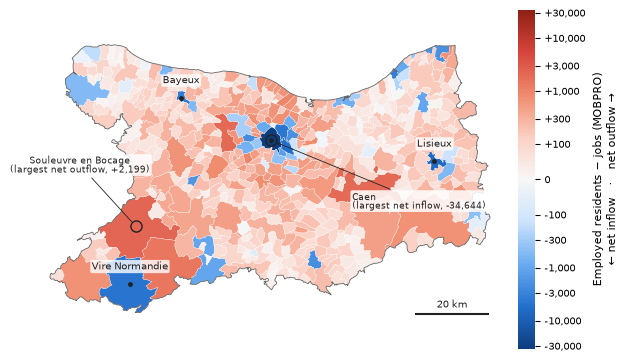

In [24]:
MARK_OFFSETS["net_commuting_mobpro_map"] = {"largest net outflow": (-15000, 14000, "center", "bottom"),
                                            "largest net inflow": (22000, -14000, "left", "top")}
mobpro_extremes = difference_map("net_mobpro", "net_commuting_mobpro_map", "Employed residents − jobs (MOBPRO)")

saved report\figures\difference_vs_mobpro.pdf


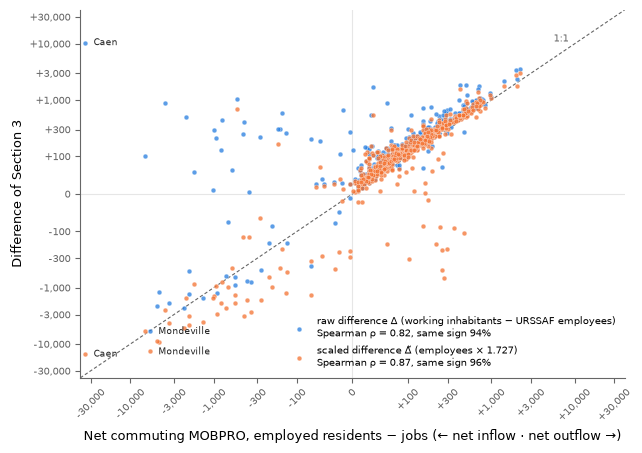

In [25]:
fig, ax = plt.subplots(figsize=(6.5, 4.6))
limit = max(df_population[["net_mobpro", "difference", "difference_scaled"]].abs().max()) * 1.15
ax.plot([-limit, limit], [-limit, limit], color=TEXT_2, lw=0.8, ls=(0, (3, 2)), zorder=1)
ax.text(10000, 10000, "1:1  ", fontsize=7, color=TEXT_2, ha="right", va="bottom")
ax.axhline(0, color=GRID, lw=0.8, zorder=0)
ax.axvline(0, color=GRID, lw=0.8, zorder=0)
for col, color, label in [("difference", BLUE, "raw difference Δ (working inhabitants − URSSAF employees)"),
                          ("difference_scaled", ORANGE, "scaled difference Δ̃ (employees × %.3f)" % scale_factor)]:
    r = agreement[col]
    ax.scatter(df_population["net_mobpro"], df_population[col], s=12, color=color, alpha=0.75,
               edgecolor="white", linewidth=0.3, zorder=2,
               label=f"{label}\nSpearman ρ = {r['spearman']:.2f}, same sign {r['share_same_sign']:.0%}")
for mid in ["14118", "14437"]:
    row = df_population.set_index("municipality_id").loc[mid]
    for col in ["difference", "difference_scaled"]:
        ax.annotate(row["name"], xy=(row["net_mobpro"], row[col]), xytext=(6, 0), textcoords="offset points",
                    fontsize=6.5, color=TEXT, va="center")
for axis in ["x", "y"]:
    getattr(ax, f"set_{axis}scale")("symlog", linthresh=SYMLOG_LINTHRESH, linscale=0.6)
ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)
ticks = [-30000, -10000, -3000, -1000, -300, -100, 0, 100, 300, 1000, 3000, 10000, 30000]
ticks = [t for t in ticks if abs(t) <= limit]
labels = [f"{t:+,}" if t else "0" for t in ticks]
ax.set_xticks(ticks, labels, fontsize=7, rotation=45)
ax.set_yticks(ticks, labels, fontsize=7)
ax.minorticks_off()
ax.set_xlabel("Net commuting MOBPRO, employed residents − jobs (← net inflow · net outflow →)")
ax.set_ylabel("Difference of Section 3")
ax.legend(loc="lower right", frameon=False, fontsize=7)   # empty quadrant: Δ < 0 where MOBPRO shows outflow
style_chart_axes(ax)
fig.tight_layout()
path = save_figure(fig, "difference_vs_mobpro", preview_png=True)
print("saved", path.relative_to(ROOT))
plt.show()

**Reading.**

- **Employed residents.** MOBPRO counts 277,131 employed residents, exactly the employed persons aged 15+ of the
  detailed census (`TACT` = 11): both are the same census records with the same weights. The working inhabitants
  (SPC 1–6) are 12.5 % higher at department level; per municipality the ratio has median 1.09 (5–95 %: 1.00–1.21)
  and the correlation is 0.9997, so the SPC definition shifts the level but hardly the pattern.
- **Jobs.** MOBPRO counts 275,908 jobs located in Calvados; URSSAF covers 65.5 % of them. Of the 95,290 jobs that
  URSSAF misses, 40 % are in Caen (73,271 jobs, URSSAF 35,246, coverage 48 %: university, CHU, administrations),
  followed by Lisieux, Bayeux, Falaise and Vire Normandie (hospitals, schools, sub-prefectures). In 38
  municipalities URSSAF has *more* employees than MOBPRO jobs, mostly commercial and industrial zones around Caen
  (Mondeville +666, Bretteville-sur-Odon +607): URSSAF counts job positions at 31 December (persons with two jobs count
  twice, temporary workers count where the agency is), MOBPRO counts persons at the place of their main job.
- **Department balance.** 30.0 % of the employed residents work in their own municipality. 21,882 residents (7.9 %)
  work outside the department (mainly Manche, Orne, Seine-Maritime, Eure, Paris) and 20,659 persons come in (mainly
  Manche, Eure, Orne): the department is almost balanced (net +1,223).
- **Net commuting.** According to MOBPRO, the **largest net inflow is Caen** (−34,644) and the **largest net outflow
  Souleuvre en Bocage** (+2,199): the two answers of the *scaled* view. The raw view has Caen with the wrong sign.
  The scaled view is closer to reality on every measure (Spearman 0.87 vs. 0.82, same sign 95.6 % vs. 94.1 %, mean
  absolute deviation 208 vs. 258 persons, Pearson 0.78 vs. −0.40). Its magnitudes are still off where the job mix
  is unusual: it halves Caen's real inflow (−15,179) and more than doubles Mondeville's (−13,525 vs. −5,785; the raw
  value −5,894 is almost exact there), because scaling assumes that every municipality has the department's mix of
  private and non-private jobs.

In [26]:
df_employment = df_population[["municipality_id", "name", "working_inhabitants", "employees", "difference",
                                "employed_residents_mobpro", "jobs_mobpro", "net_mobpro"]].copy()
df_employment = df_employment.sort_values("municipality_id").reset_index(drop=True)
assert len(df_employment) == 528 and list(df_employment["municipality_id"]) == list(df_municipalities["municipality_id"])
df_employment.to_parquet(EMPLOYMENT_PARQUET)
print("saved", EMPLOYMENT_PARQUET.relative_to(ROOT), df_employment.shape)

# Origin-destination flows with both ends in the department, summed over the modes (course notebook format)
df_commutes = (df_mobpro[lives_in & works_in].groupby(["origin_id", "destination_id"])["weight"].sum()
               .reset_index())
assert set(df_commutes["origin_id"]) <= ours and set(df_commutes["destination_id"]) <= ours
assert np.isclose(df_commutes["weight"].sum(), mobpro_totals["living_and_working_in_department"])
df_commutes.to_parquet(COMMUTES_PARQUET)
print("saved", COMMUTES_PARQUET.relative_to(ROOT), df_commutes.shape,
      f"| persons {df_commutes['weight'].sum():,.1f} | intra-municipal {df_commutes.loc[df_commutes['origin_id'] == df_commutes['destination_id'], 'weight'].sum():,.1f}")

mobpro_cols = ["name", "employed_residents_mobpro", "jobs_mobpro", "net_mobpro", "working_inhabitants",
               "employees", "difference", "difference_scaled"]
results["mobpro_validation"] = {
    "source": {"title": "INSEE, RP2019, Mobilités professionnelles des individus (MOBPRO), geography 2021",
               "url": MOBPRO_URL, "file": MOBPRO_CSV.name},
    "n_rows_france": int(n_rows_france),
    "persons_france": float(weight_france),
    "n_rows_kept": int(len(df_mobpro)),
    "codes_not_in_528": codes_not_ours,
    "municipalities_without_employed_residents": ours_without_residents,
    "municipalities_without_jobs": ours_without_jobs,
    "totals": {k: float(v) for k, v in mobpro_totals.items()},
    "shares": {k: float(v) for k, v in mobpro_shares.items()},
    "outside_work_by_department": {k: float(v) for k, v in outside_work.head(6).items()},
    "outside_home_by_department": {k: float(v) for k, v in outside_home.head(6).items()},
    "employed_residents": {
        "mobpro": float(employed_mobpro_total),
        "census_employed_15p_tact": float(employed_15p),
        "ratio_mobpro_to_tact": float(employed_mobpro_total / employed_15p),
        "working_inhabitants": float(working_total),
        "ratio_working_to_mobpro": float(working_total / employed_mobpro_total),
        "pearson_per_municipality": float(pearson_residents),
        "ratio_per_municipality_median": float(ratio_working_to_mobpro.median()),
        "ratio_per_municipality_p05": float(ratio_working_to_mobpro.quantile(0.05)),
        "ratio_per_municipality_p95": float(ratio_working_to_mobpro.quantile(0.95)),
    },
    "jobs": {
        "mobpro": float(jobs_mobpro_total),
        "urssaf": float(employees_total),
        "coverage_urssaf_to_mobpro": float(coverage_total),
        "pearson_per_municipality": float(pearson_jobs),
        "coverage_per_municipality_median": float(df_population["coverage_urssaf"].median()),
        "n_urssaf_above_mobpro": int((df_population["jobs_missed_urssaf"] < 0).sum()),
        "missed_total": float(missed_total),
        "caen_missed": float(caen_missed),
        "caen_missed_share": float(caen_missed / missed_total),
        "top_missed": records(top_missed, ["name", "jobs_mobpro", "employees", "jobs_missed_urssaf",
                                           "coverage_urssaf"]),
    },
    "net": {
        "agreement": {k: {m: float(v) for m, v in d.items()} for k, d in agreement.items()},
        "n_outflow": int((net > 0).sum()),
        "n_inflow": int((net < 0).sum()),
        "sum": float(net.sum()),
        "largest_outflow": mobpro_extremes[0],
        "largest_inflow": mobpro_extremes[1],
        "top_outflow": records(mobpro_outflow, mobpro_cols),
        "top_inflow": records(mobpro_inflow, mobpro_cols),
        "towns": records(df_population[df_population["municipality_id"].isin(TOWNS)], mobpro_cols),
        "ranks_of_section3_extremes": {
            label: {"municipality_id": mid, "net_mobpro": float(net[df_population["municipality_id"] == mid].iloc[0]),
                    "outflow_rank": int(rank_outflow[df_population["municipality_id"] == mid].iloc[0]),
                    "inflow_rank": int(rank_inflow[df_population["municipality_id"] == mid].iloc[0])}
            for label, mid in [("raw_outflow", raw_extremes[0]), ("raw_inflow", raw_extremes[1]),
                               ("scaled_outflow", scaled_extremes[0]), ("scaled_inflow", scaled_extremes[1])]},
    },
    "commutes_parquet": {"n_pairs": int(len(df_commutes)), "persons": float(df_commutes["weight"].sum())},
}
RESULTS_JSON.write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding="utf-8")
print("saved", RESULTS_JSON.relative_to(ROOT))

saved data\processed\employment_14.parquet (528, 8)
saved data\processed\commutes_14.parquet (9866, 3) | persons 255,249.0 | intra-municipal 83,262.7
saved data\processed\ex13_results.json


## Problems encountered

- **Definition of working inhabitants.** The aggregated census has no count of employed persons, only the population
  15+ by SPC, and the SPC also classifies persons by a former occupation. Measured with `TACT` in the detailed census
  (Section 1): 88.9 % of the persons in SPC 1–6 are employed and 11.1 % unemployed; no other status occurs. Working
  inhabitants therefore exceed the employed residents by 12.5 %, much less than the gap between census and URSSAF
  (URSSAF = 58 % of the working inhabitants, 65 % of the employed persons).
- **Different geography.** URSSAF uses the current municipality geography, the project the geography of 2021.
  Recoded with the INSEE COG 2026 list of changes: Aurseulles changed its code from 14011 to 14581 (24/04/2024, new
  chef-lieu); Saint-Martin-de-Fontenay (14623) merged with May-sur-Orne into Saint-Martin-de-May (14408) and Gerrots
  (14300) into Victot-en-Auge (14743), both on 01/01/2025. URSSAF only reports the merged totals (406 and 12
  employees), which were split in proportion to working inhabitants (an assumption).
- **Municipalities without URSSAF row.** 10 small municipalities (48 to 216 inhabitants) have no row at all and get 0
  employees; 45 more have rows but 0 employees in 2019 (55 with 0 in total).
- **Empty values in the URSSAF file.** 7,480 municipality × sector rows have no 2019 value. 7,476 of them also have
  no establishment in 2019 (the sector appears in that municipality only in other years); 4 rows have one
  establishment but no employee count. All are counted as 0.
- **Definitions do not match.** URSSAF counts private-sector salaried jobs at the workplace (180,618), the census
  all working residents (311,886): the ratio is 0.58. The raw difference is therefore positive almost everywhere,
  and Caen, which concentrates public-sector jobs (university, hospital, administrations) that URSSAF does not count,
  appears as the largest net *outflow*. The scaled view removes the level difference but assumes that the missing
  (public, self-employed, agricultural) jobs are distributed like private salaried jobs.